In [11]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import charge_trap_pot_model as ctm 
import time


np.set_printoptions(threshold=sys.maxsize)

In [12]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)

ModCT = ctm.Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, t_ox=7, t_sige=48)


lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418


In [13]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
#XCT = np.linspace(0, (NTOT)*AX, 35)
XCT = (NSC+NSM/2)*AX

# Define the boundary points
a = -100*AY
b = 0
c = M*AY
d = (M+100)*AY

# Define the number of points between each segment
n_ab = 50  # number of points between a and b
n_bc = 101  # number of points between b and c (more points)
n_cd = 50  # number of points between c and d

#n_ab = 5  # number of points between a and b
#n_bc = 11  # number of points between b and c (more points)
#n_cd = 5  # number of points between c and d




# Create linearly spaced points between each pair
y_ab = np.linspace(a, b, n_ab, endpoint=False)
y_bc = np.linspace(b, c, n_bc, endpoint=False)
y_cd = np.linspace(c, d, n_cd, endpoint=True)

# Concatenate all points
YCT = np.concatenate((y_ab, y_bc, y_cd))

#print(YCT)

print('X co-ordinate of charge trap =', XCT )

ZCT = 7
ZIM = 0   ### immaterial in img charge model 
ZQW = 57

Ep = np.empty((YCT.shape[0],K_NUM))

for i in range(YCT.shape[0]):

    H = ModCT.H_sys(PHI, 'cu', XCT, YCT[i], ZCT, ZIM, ZQW, f_ct=1)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep[i,:] = Es

    #if i %10 ==0 :
    if i %1 ==0 :
        print(Ep[i,:])

#np.save('cubic_E_vs_yct_image_chrg_model.npy', Ep)
np.save('cubic_E_vs_yct_image_chrg_model_full.npy', Ep)

X co-ordinate of charge trap = 4150.0
[-0.16624554 -0.16621114 -0.07575085 -0.07545334  0.07545334  0.07575085
  0.16621114  0.16624554]
[-0.16624551 -0.1662111  -0.07575043 -0.07545291  0.07545291  0.07575043
  0.1662111   0.16624551]
[-0.16624547 -0.16621106 -0.07574997 -0.07545247  0.07545247  0.07574997
  0.16621106  0.16624547]
[-0.16624544 -0.16621102 -0.0757495  -0.07545199  0.07545199  0.0757495
  0.16621102  0.16624544]
[-0.1662454  -0.16621098 -0.07574899 -0.07545149  0.07545149  0.07574899
  0.16621098  0.1662454 ]
[-0.16624536 -0.16621093 -0.07574844 -0.07545095  0.07545095  0.07574844
  0.16621093  0.16624536]
[-0.16624531 -0.16621089 -0.07574786 -0.07545037  0.07545037  0.07574786
  0.16621089  0.16624531]
[-0.16624526 -0.16621083 -0.07574724 -0.07544976  0.07544976  0.07574724
  0.16621083  0.16624526]
[-0.16624521 -0.16621078 -0.07574658 -0.07544911  0.07544911  0.07574658
  0.16621078  0.16624521]
[-0.16624516 -0.16621072 -0.07574588 -0.07544841  0.07544841  0.07574588

In [5]:
#Ep_cu_mm2d = np.load('cubic_E_vs_yct_Zdiff_14_wider_yct_width_75nm_refined.npy')
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
#XCT = np.linspace(0, (NTOT)*AX, 35)
XCT = (NSC+NSM/2)*AX

# Define the boundary points
a = -100*AY
b = 0
c = M*AY
d = (M+100)*AY

# Define the number of points between each segment
n_ab = 50  # number of points between a and b
n_bc = 101  # number of points between b and c (more points)
n_cd = 50  # number of points between c and d

#n_ab = 5  # number of points between a and b
#n_bc = 11  # number of points between b and c (more points)
#n_cd = 5  # number of points between c and d




# Create linearly spaced points between each pair
y_ab = np.linspace(a, b, n_ab, endpoint=False)
y_bc = np.linspace(b, c, n_bc, endpoint=False)
y_cd = np.linspace(c, d, n_cd, endpoint=True)

# Concatenate all points
YCT = np.concatenate((y_ab, y_bc, y_cd))

#print(YCT)

print('X co-ordinate of charge trap =', XCT )

ZCT = 7
ZIM = 0   ### immaterial in img charge model 
ZQW = 57


Ep_cu_ctm = np.load('cubic_E_vs_yct_image_chrg_model_full.npy')

X co-ordinate of charge trap = 4150.0


Text(0, 0.5, '$\\dfrac{E_s}{E_{s0}}$')

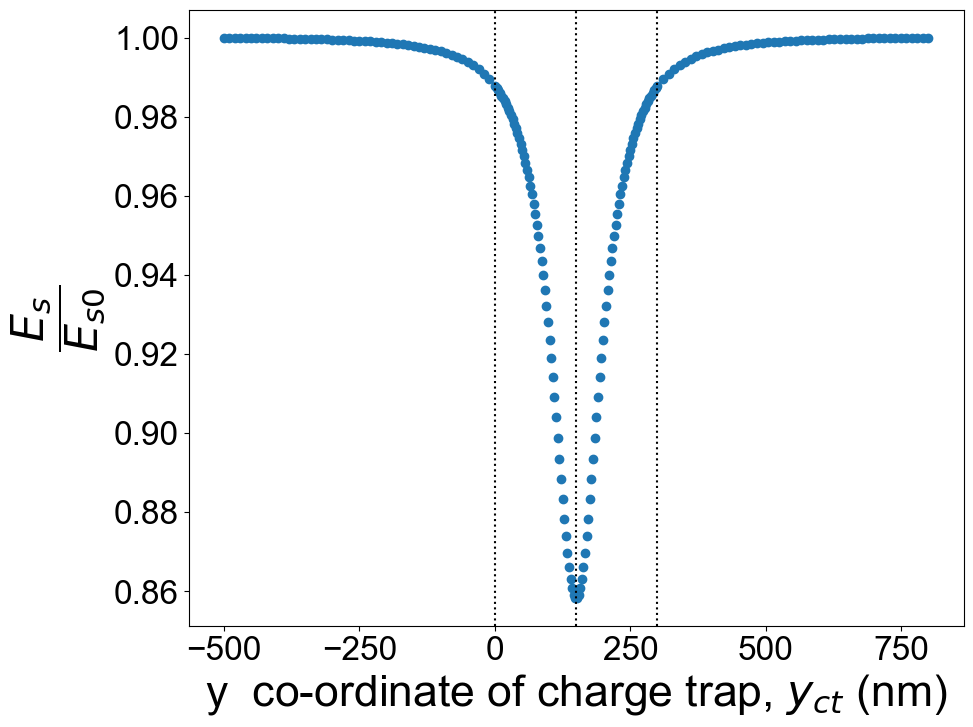

In [15]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

ax = plt.axis()

#cubic_spin_split = Ep_cu_ctm[:, K_NUM//2+1]-Ep_cu_ctm[:, K_NUM//2]
cubic_spin_split = Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)


Ep_wct = (Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])/max_spin_split

plt.scatter(YCT, Ep_wct )
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')
plt.axvline(x=M/2*AY, color='black', linestyle='dotted')

plt.xlabel(r'y  co-ordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)

In [7]:
print(YCT)

[-500.         -490.         -480.         -470.         -460.
 -450.         -440.         -430.         -420.         -410.
 -400.         -390.         -380.         -370.         -360.
 -350.         -340.         -330.         -320.         -310.
 -300.         -290.         -280.         -270.         -260.
 -250.         -240.         -230.         -220.         -210.
 -200.         -190.         -180.         -170.         -160.
 -150.         -140.         -130.         -120.         -110.
 -100.          -90.          -80.          -70.          -60.
  -50.          -40.          -30.          -20.          -10.
    0.            2.97029703    5.94059406    8.91089109   11.88118812
   14.85148515   17.82178218   20.79207921   23.76237624   26.73267327
   29.7029703    32.67326733   35.64356436   38.61386139   41.58415842
   44.55445545   47.52475248   50.4950495    53.46534653   56.43564356
   59.40594059   62.37623762   65.34653465   68.31683168   71.28712871
   74.25742574 

In [8]:
print(YCT[np.argmin(Ep_wct)])

154.45544554455446


make sure to inclue center point 150 in YCT

In [2]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)

ModCT = ctm.Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, t_ox=7, t_sige=48)

#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
#XCT = np.linspace(0, (NTOT)*AX, 35)
XCT = (NSC+NSM/2)*AX

##checking teh minimum for small range first 

YCT = np.array([148.51485149 , 150, 151.48514851, 154.45544554]) 

#print(YCT)

print('X co-ordinate of charge trap =', XCT )

ZCT = 7
ZIM = 0   ### immaterial in img charge model 
ZQW = 57

Ep = np.empty((YCT.shape[0],K_NUM))

for i in range(YCT.shape[0]):

    H = ModCT.H_sys(PHI, 'cu', XCT, YCT[i], ZCT, ZIM, ZQW, f_ct=1)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep[i,:] = Es

    #if i %10 ==0 :
    if i %1 ==0 :
        print(Ep[i,:])

#np.save('cubic_E_vs_yct_image_chrg_model.npy', Ep)
np.save('cubic_E_vs_yct_image_chrg_model_centering_check.npy', Ep)

lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418
X co-ordinate of charge trap = 4150.0
[-0.16501527 -0.1649352  -0.07562671 -0.07537134  0.07537134  0.07562671
  0.1649352   0.16501527]
[-0.16501355 -0.16493344 -0.07563019 -0.07537484  0.07537484  0.07563019
  0.16493344  0.16501355]
[-0.16501527 -0.1649352  -0.07562671 -0.07537134  0.07537134  0.07562671
  0.1649352   0.16501527]
[-0.1650289  -0.16494921 -0.0755992  -0.07534358  0.07534358  0.0755992
  0.16494921  0.1650289 ]


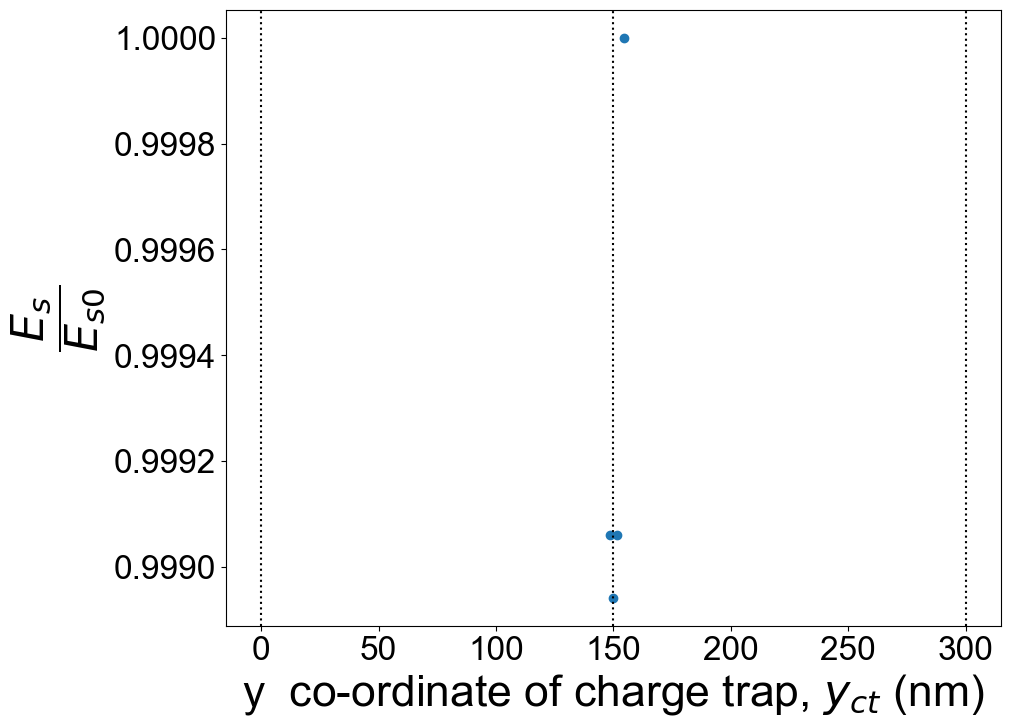

In [10]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))

ax = plt.axis()

cubic_spin_split = Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)


Ep_wct = (Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])/max_spin_split

plt.scatter(YCT, Ep_wct )
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')
plt.axvline(x=M/2*AY, color='black', linestyle='dotted')

plt.xlabel(r'y  co-ordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)
plt.savefig('charge_trap_ES_center_check.png')
#plt.show()